# Logistic regression

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anatole-1/exercices-machine-learning/blob/main/02_logistic_regression.ipynb)

1. Exercise 1 – Breast Cancer Wisconsin (2 classes, 30 variables)
2. Exercise 2 – Wine recognition (3 classes, 13 variables)
3. Exercise 3 – Non-linear decision boundary with quadratic features

Run the notebook from the repository folder (the data files are in `data/`). In Google Colab, the first code cell clones the repository automatically.

In [ ]:
# Google Colab: get the data files by cloning the repository
import os, subprocess
if 'google.colab' in str(get_ipython()) and not os.path.exists('data'):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Anatole-1/exercices-machine-learning.git'], check=True)
    os.chdir('exercices-machine-learning')

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng=np.random.default_rng() #seed = random

## Exercise 1


[Breast cancer wisconsin (diagnostic) dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset) 569 datapoints, 30 variables, 2 classes



$$
x^{(i)}=[x^{(i)}_1,x_2^{(i)},...,x_{30}^{(i)}],\quad y^{(i)}=0,1
$$


$$
$$

Attribute Information:

    radius (mean of distances from center to points on the perimeter)

    texture (standard deviation of gray-scale values)

    perimeter

    area

    smoothness (local variation in radius lengths)

    compactness (perimeter^2 / area - 1.0)

    concavity (severity of concave portions of the contour)

    concave points (number of concave portions of the contour)

    symmetry

    fractal dimension (“coastline approximation” - 1)

The mean, standard error, and “worst” or largest (mean of the three worst/largest values) of these features were computed for each image, resulting in 30 features. For instance, field 0 is Mean Radius, field 10 is Radius SE, field 20 is Worst Radius.




    class:

            WDBC-Malignant

            WDBC-Benign



In [ ]:
#load the dataset
from sklearn import datasets
X,y=datasets.load_breast_cancer(return_X_y=True)
#rows of X are the coordinates x1...x30
#y contains the classes 0,1

Draw a picture like below of the distributions of the values of coordinates $x_1,..,x_{30}$

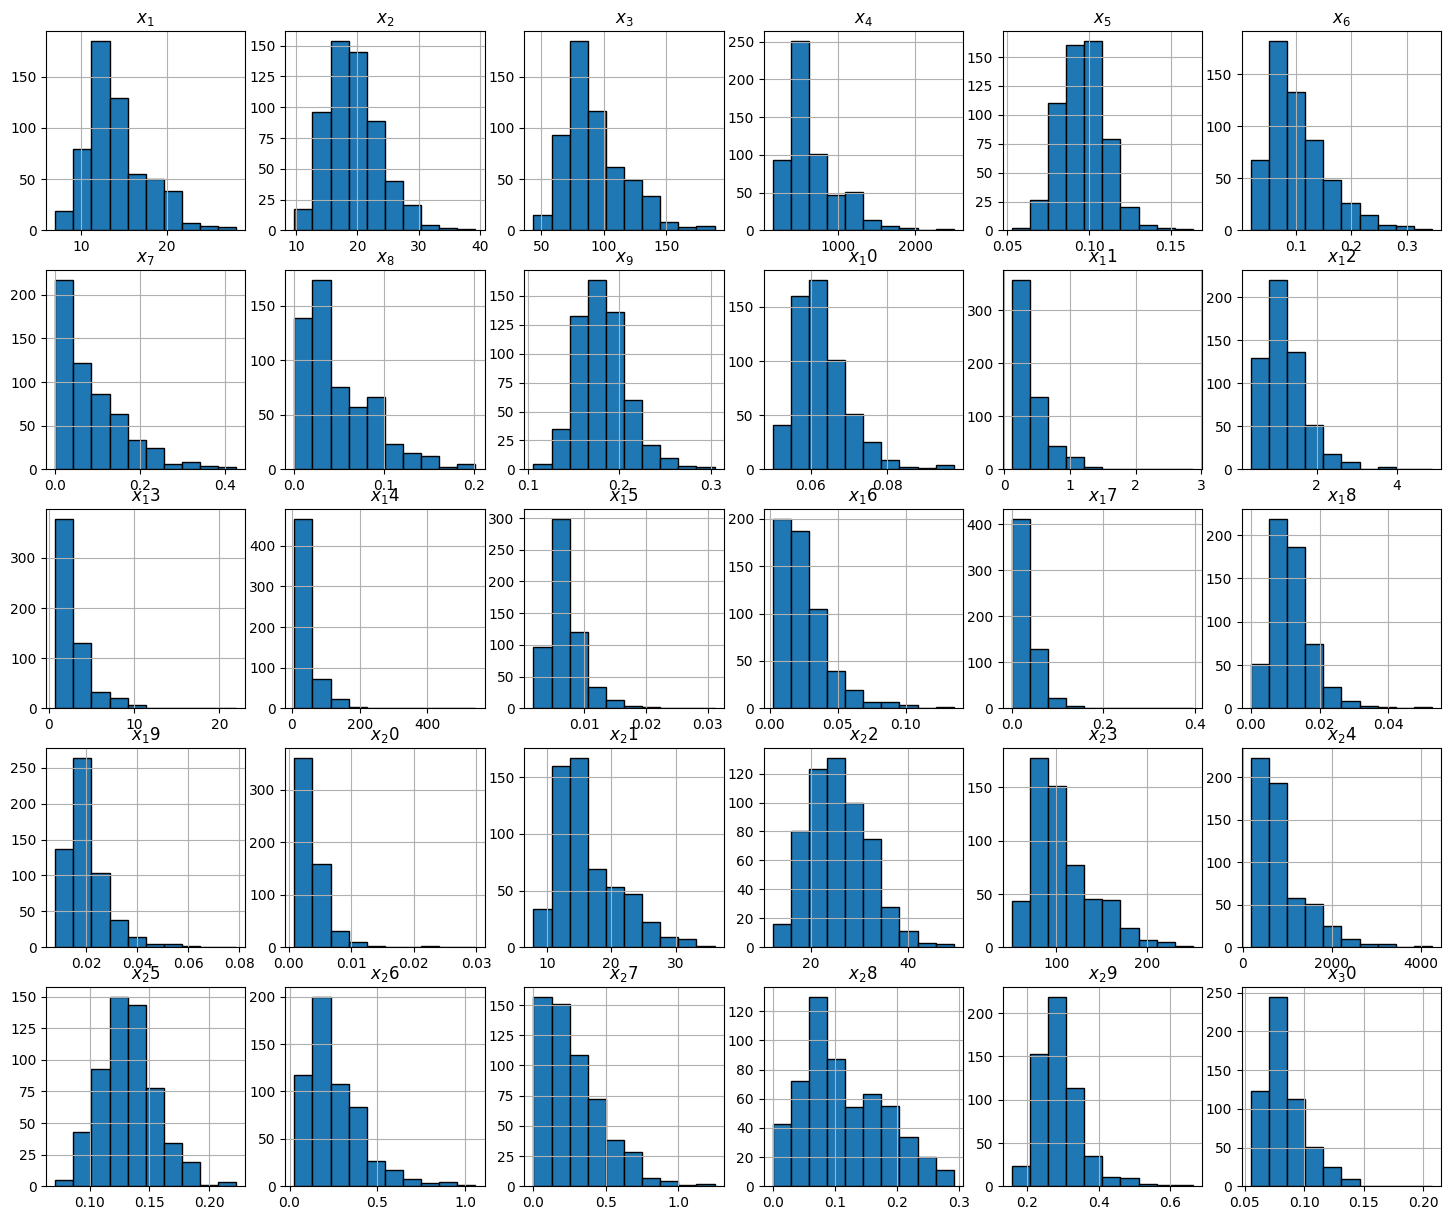

In [ ]:
plt.figure(figsize=(18, 15))

for k in range(30):
    plt.subplot(5, 6, k + 1)
    plt.hist(X[:, k], bins=10, edgecolor='k')
    plt.grid()
    plt.title(r'$x_{}$'.format(k + 1))

plt.show()

![figure](images/02_ex1_1.png)

Find coefficients to a formula

$$
z=w_1\widehat{x}_1+w_2\widehat{x}_2+\dots+w_{30}\widehat{x}_{30}+b
$$

for the classification of a point $x=[x_1,x_2,...,x_{30}]$ using the scaled coordinates (means $=0$ and standard deviations $=1$)
and draw a picture like below:

In [ ]:
# scaled coordinates, means = 0 and stds = 1
mu = np.mean(X, axis=0)
s = np.std(X, axis=0)
Xhat = (X - mu) / s

beta = 1
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(C=1/beta).fit(Xhat, y)

w = model.coef_[0]
b = model.intercept_[0]

np.set_printoptions(precision=3, suppress=True)
print("w =", w)
print("b =", b)

w = [-0.375 -0.382 -0.361 -0.439 -0.167  0.561 -0.855 -0.963  0.076  0.328
 -1.289  0.265 -0.672 -0.999 -0.28   0.744  0.101 -0.323  0.295  0.682
 -1.027 -1.321 -0.82  -0.995 -0.666  0.051 -0.88  -0.925 -0.889 -0.487]
b = 0.22088610964219607


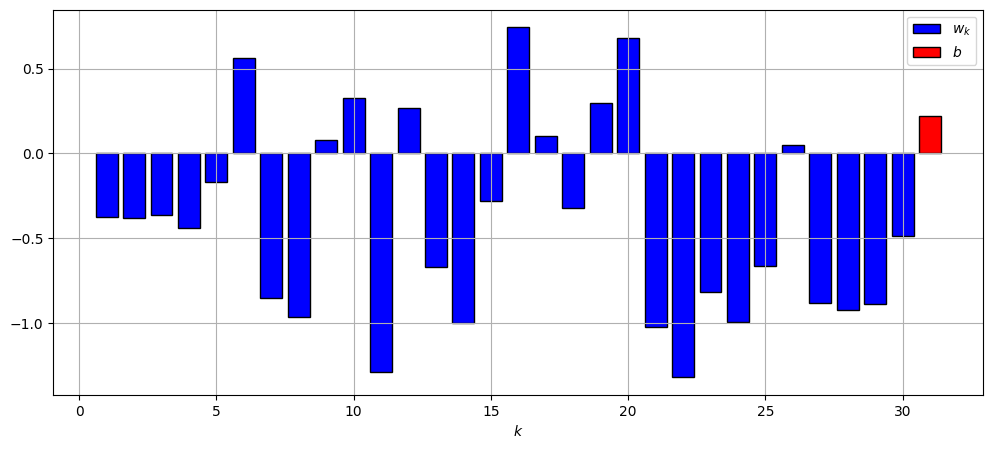

In [ ]:
plt.figure(figsize=(12, 5))
plt.bar(np.arange(1, 31), w, color='b', edgecolor='k', label=r'$w_k$')
plt.bar(31, b, color='r', edgecolor='k', label=r'$b$')
plt.grid()
plt.xlabel(r'$k$')
plt.legend()
plt.show()

![figure](images/02_ex1_2.png)

Create the confusion matrix

$$
$$

ans: $
 \left[\begin{array}{cc}
207&   5\\
2&355
\end{array}\right]
$


$$
$$


and classify the point

$x=[ 13.61    ,  24.98    ,  88.05    , 582.7     ,   0.09488 ,
         0.08511 ,   0.08625 ,   0.04489 ,   0.1609  ,   0.05871 ,
         0.4565  ,   1.29    ,   2.861   ,  43.14    ,   0.005872,
         0.01488 ,   0.02647 ,   0.009921,   0.01465 ,   0.002355,
        16.99    ,  35.27    , 108.6     , 906.5     ,   0.1265  ,
         0.1943  ,   0.3169  ,   0.1184  ,   0.2651  ,   0.07397 ]$


$$
$$

ans: $y=0$

In [ ]:
from sklearn.metrics import confusion_matrix

ypred = model.predict(Xhat)
cm = confusion_matrix(y, ypred)

print(cm)

[[207   5]
 [  2 355]]


In [ ]:
xt = np.array([[13.61    , 24.98    , 88.05    , 582.7     , 0.09488 ,
                0.08511 , 0.08625  , 0.04489  , 0.1609   , 0.05871 ,
                0.4565  , 1.29     , 2.861    , 43.14    , 0.005872,
                0.01488 , 0.02647  , 0.009921 , 0.01465  , 0.002355,
                16.99   , 35.27    , 108.6    , 906.5    , 0.1265  ,
                0.1943  , 0.3169   , 0.1184   , 0.2651   , 0.07397 ]])

xthat = (xt - mu) / s
ytpred = model.predict(xthat)
print("predicted class =", ytpred)

apred = model.predict_proba(xthat)
print("probabilities =", apred)

predicted class = [0]
probabilities = [[0.962 0.038]]


## Exercise 2


[Wine recognition-dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html), 178 datapoints, 13 variables, 3 classes

$$
x^{(i)}=[x_1^{(i)},x_2^{(i)},...,x_{13}^{(i)}],\quad y^{(i)}=0,1,2
$$

Wine data set of chemical properties of Italian
wines. The data set includes measurements of 13 different
properties for 178 wines, giving a data matrix of
dimension 178 x 13.

1) Alcohol

2) Malic acid

3) Ash

4) Alcalinity of ash

5) Magnesium

6) Total phenols

7) Flavanoids

8) Nonflavanoid phenols

9) Proanthocyanins

10) Color intensity

11) Hue

12) OD280/OD315 of diluted wines

13) Proline

Each of these 178 wines comes from one of three grape
varieties: Barolo, Grignolino, or Barbera (0,1 tai 2).

In [ ]:
#load the dataset
from sklearn import datasets
X,y=datasets.load_wine(return_X_y=True)
#rows of X are the coordinates x1...x13
#y contains the classes 0,1,2

Draw a picture like below of the distribution of values of the coordinates $x_1-x_{13}$ within each class

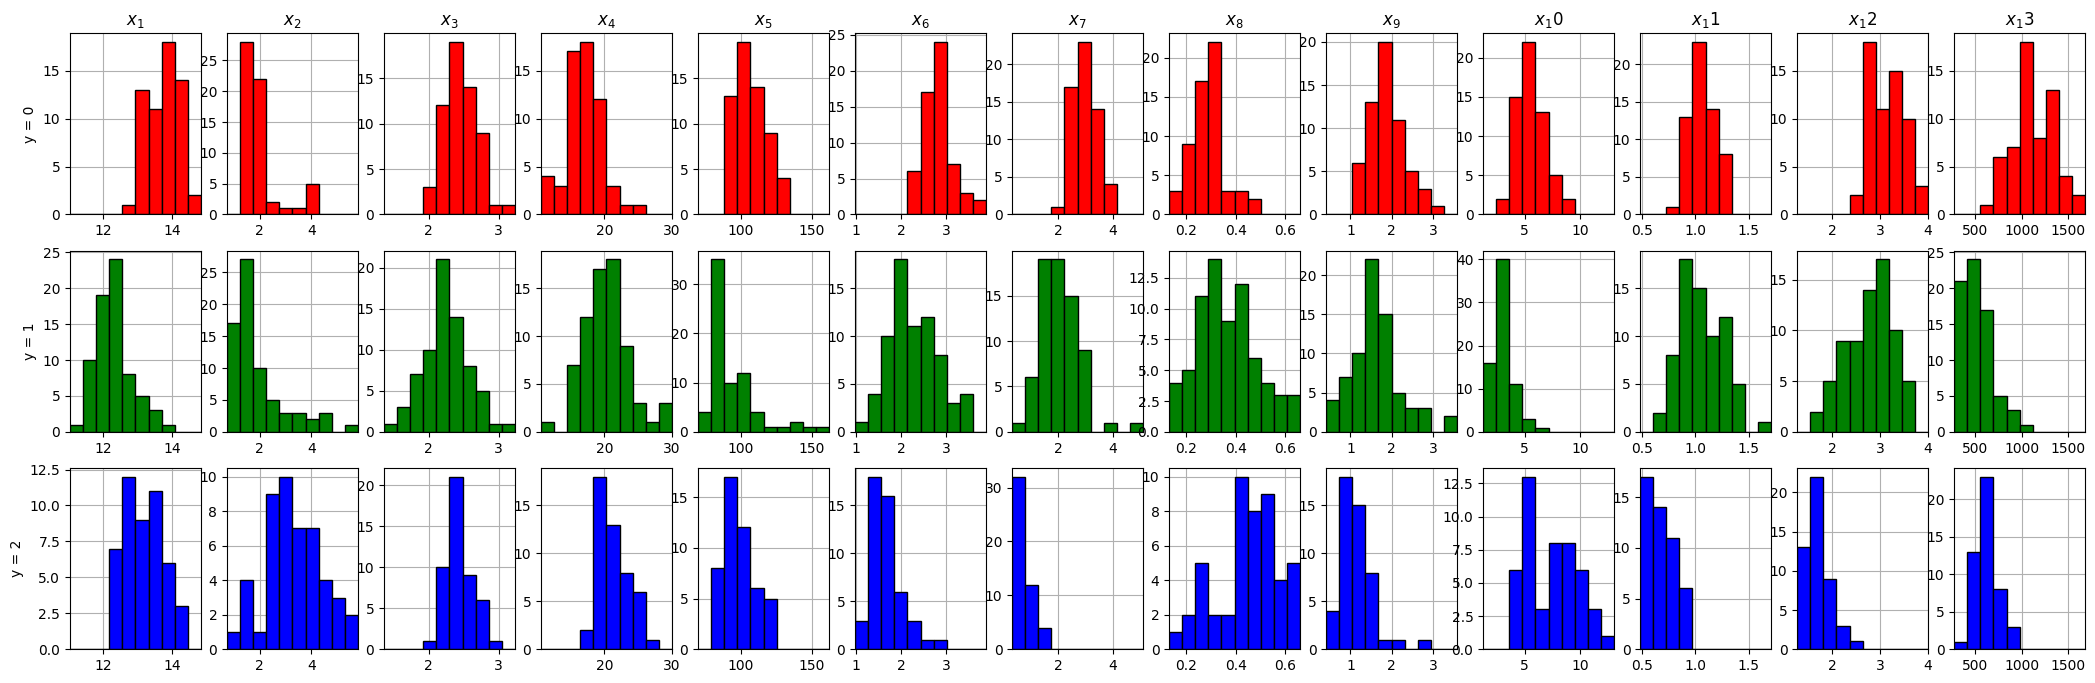

In [ ]:
plt.figure(figsize=(26, 8))

for k in range(13):
    mk = np.min(X[:, k])
    Mk = np.max(X[:, k])
    binsk = np.linspace(mk, Mk, 11)

    plt.subplot(3, 13, k + 1)
    plt.hist(X[y == 0, k], binsk, edgecolor='k', color='r', zorder=2)
    plt.grid()
    plt.xlim(mk, Mk)
    plt.title(r'$x_{}$'.format(k + 1))
    if k == 0:
        plt.ylabel('y = 0')

    plt.subplot(3, 13, k + 14)
    plt.hist(X[y == 1, k], binsk, edgecolor='k', color='g', zorder=2)
    plt.grid()
    plt.xlim(mk, Mk)
    if k == 0:
        plt.ylabel('y = 1')

    plt.subplot(3, 13, k + 27)
    plt.hist(X[y == 2, k], binsk, edgecolor='k', color='b', zorder=2)
    plt.grid()
    plt.xlim(mk, Mk)
    if k == 0:
        plt.ylabel('y = 2')

plt.show()

![figure](images/02_ex2_1.png)

Find coefficients to the formula

$$
[z_1,z_2,z_3]=[\widehat{x}_1,\widehat{x}_2,...,\widehat{x}_{13}]@\left[
\begin{array}{ccc}
w_{11}&w_{12}&w_{13}\\
w_{21}&w_{22}&w_{23}\\
\vdots&\vdots&\vdots\\
w_{13,1}&w_{13,2}&w_{13,3}
\end{array}
\right]+[b_1,b_2,b_3]
$$

to classify a wine $ x=[x_1,x_2,\dots,x_{13}]$ using the scaled coordinates  (means $= 0$ and standard deviations $= 1$), and draw a picture like below.



In [ ]:
# scaled coordinates, means = 0 and stds = 1
mu = np.mean(X, axis=0)
s = np.std(X, axis=0)
Xhat = (X - mu) / s

beta = 0.01
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(C=1/beta).fit(Xhat, y)

w = model.coef_.T   # transpose: one column per class
b = model.intercept_

np.set_printoptions(precision=3, suppress=True)
print("w =")
print(w)
print()
print("b =", b)

w =
[[ 1.915 -2.363  0.447]
 [ 0.839 -1.015  0.176]
 [ 1.415 -2.533  1.118]
 [-2.382  1.805  0.577]
 [ 0.261  0.112 -0.372]
 [ 0.129 -0.233  0.104]
 [ 1.661  1.205 -2.867]
 [-0.446  1.073 -0.627]
 [ 0.259  0.441 -0.7  ]
 [ 0.137 -3.274  3.136]
 [ 0.355  1.901 -2.255]
 [ 1.97  -0.103 -1.868]
 [ 2.938 -3.412  0.474]]

b = [ 0.786  0.8   -1.587]


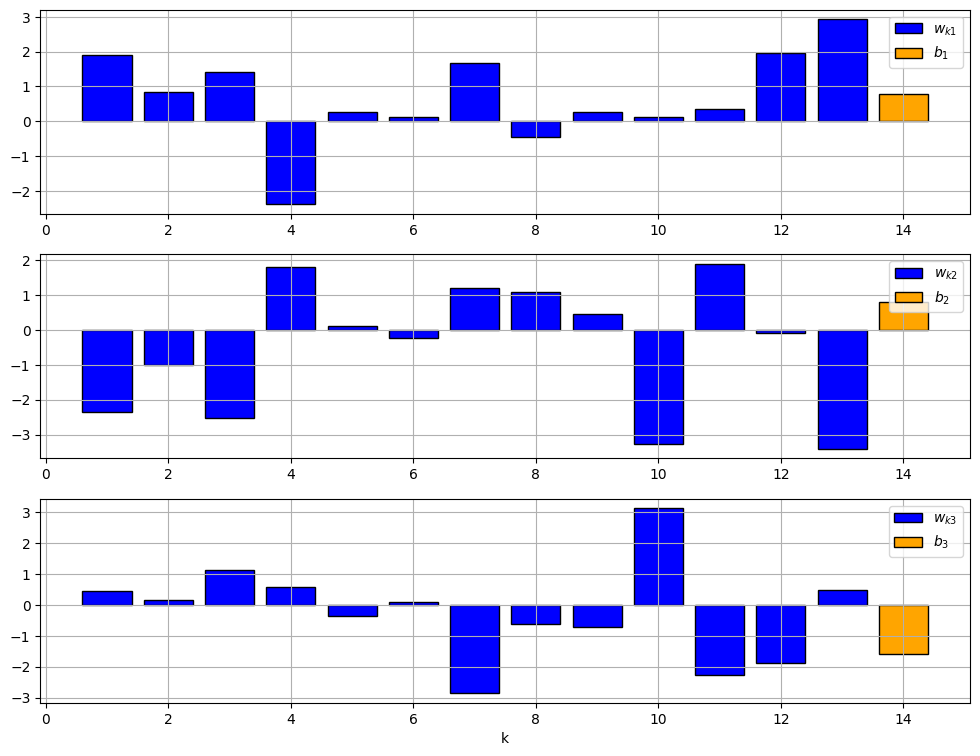

In [ ]:
plt.figure(figsize=(12, 9))

for j in range(3):
    plt.subplot(3, 1, j + 1)
    plt.bar(np.arange(1, 14), w[:, j], color='b', edgecolor='k', label=fr'$w_{{k{j+1}}}$')
    plt.bar(14, b[j], color='orange', edgecolor='k', label=fr'$b_{j+1}$')
    plt.grid()
    plt.legend(loc='upper right')
    if j == 2:
        plt.xlabel('k')

plt.show()

![figure](images/02_ex2_2.png)

Create the  confusion matrix

ans: $\left[\begin{array}{ccc}
59&0&0\\0&71&0\\0&0&48
\end{array}\right]$

In [ ]:
from sklearn.metrics import confusion_matrix

ypred = model.predict(Xhat)
cm = confusion_matrix(y, ypred)

print(cm)

[[59  0  0]
 [ 0 71  0]
 [ 0  0 48]]


and classify the wine

$x=[13.0,2.34,2.36,19.5,99.7,2.29,2.03,0.36,1.59,5.1,0.96,2.61,746]$

(ans: $y=1$)

In [ ]:
xt = np.array([[13.0, 2.34, 2.36, 19.5, 99.7, 2.29, 2.03, 0.36, 1.59, 5.1, 0.96, 2.61, 746]])

xthat = (xt - mu) / s
ytpred = model.predict(xthat)

print("predicted class =", ytpred)

apred = model.predict_proba(xthat)
print("probabilities =", apred)

predicted class = [1]
probabilities = [[0.461 0.494 0.045]]


## Exercise 3


Use the points $x^{(i)}=[x_1^{(i)},x_2^{(i)}],\,y^{(i)}=0,1,$ given below to find coefficients $w_1,w_2,w_3,w_4,w_5$ and $b$ such that a point $x=[x_1,x_2]$ belongs to

class $y=1$, if
$z=w_1x_1^2+w_2x_1x_2+w_3x_2^2+w_4x_1+w_5x_2+b> 0$

class $y=0$, if $z<0$


using logistic regression for the datapoints

 $$[(x^{(i)}_1)^2,x^{(i)}_1x^{(i)}_2,(x^{(i)}_2)^2,x^{(i)}_1,x^{(i)}_2 ],\quad y^{(i)}$$

and draw pictures like below of the corresponding classification of 2D-points

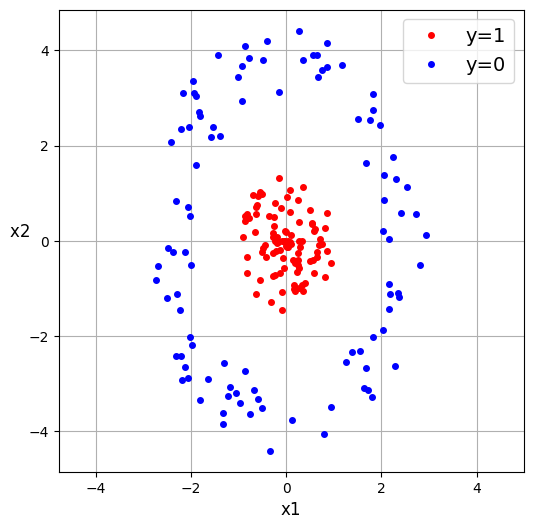

In [ ]:
#points

k=100
r1=rng.uniform(0,1,k)
th1=rng.uniform(0,2*np.pi,k)
x1pun=r1*np.cos(th1)
x2pun=1.5*r1*np.sin(th1)

r2=2+rng.uniform(0,1,k)
th2=rng.uniform(0,2*np.pi,k)
x1sin=r2*np.cos(th2)
x2sin=1.5*r2*np.sin(th2)


plt.figure(figsize=(6,6))
plt.plot(x1pun,x2pun,'r.',markersize=8,label='y=1')
plt.plot(x1sin,x2sin,'b.',markersize=8,label='y=0')
plt.grid()
plt.axis('equal')
plt.legend(fontsize=14)
plt.xlabel('x1',fontsize=12)
plt.ylabel('x2 ',rotation=0,fontsize=12)
plt.show()

In [ ]:
# datapoints and classes
x1 = np.concatenate((x1pun, x1sin))
x2 = np.concatenate((x2pun, x2sin))
y = np.concatenate((np.ones(k, dtype=int), np.zeros(k, dtype=int)))

# transformed coordinates:
# [x1^2, x1*x2, x2^2, x1, x2]
X = np.column_stack((x1**2, x1*x2, x2**2, x1, x2))

from sklearn.linear_model import LogisticRegression

beta = 0.001
model = LogisticRegression(C=1/beta).fit(X, y)

w = model.coef_[0]
b = model.intercept_[0]

np.set_printoptions(precision=3, suppress=True)
print("w =", w)
print("b =", b)

w = [-4.55   0.028 -1.939 -0.075 -0.02 ]
b = 11.286608034574828


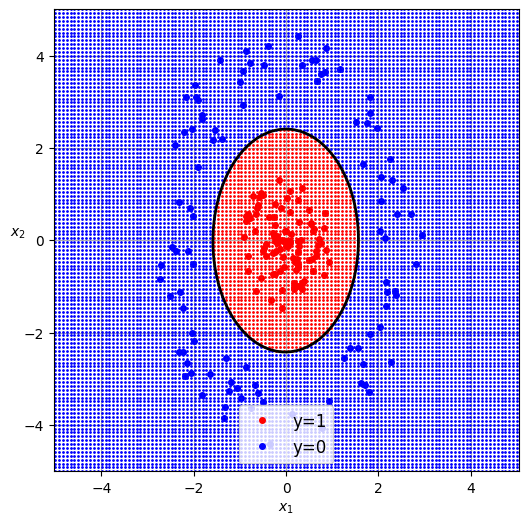

In [ ]:
# grid of 2D points for classification picture
u = np.linspace(-5, 5, 120)
v = np.linspace(-5, 5, 120)
U, V = np.meshgrid(u, v)

Xgrid = np.column_stack((U.ravel()**2,
                         U.ravel()*V.ravel(),
                         V.ravel()**2,
                         U.ravel(),
                         V.ravel()))

ygrid = model.predict(Xgrid)

# corresponding z-values
Z = (w[0]*U**2 + w[1]*U*V + w[2]*V**2 + w[3]*U + w[4]*V + b)

plt.figure(figsize=(6, 6))
plt.plot(U.ravel()[ygrid == 1], V.ravel()[ygrid == 1], 'r.', markersize=2)
plt.plot(U.ravel()[ygrid == 0], V.ravel()[ygrid == 0], 'b.', markersize=2)

plt.plot(x1pun, x2pun, 'r.', markersize=8, label='y=1')
plt.plot(x1sin, x2sin, 'b.', markersize=8, label='y=0')

plt.contour(U, V, Z, levels=[0], colors='k', linewidths=2)

plt.grid()
plt.axis('equal')
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$', rotation=0)
plt.legend(fontsize=12)
plt.show()

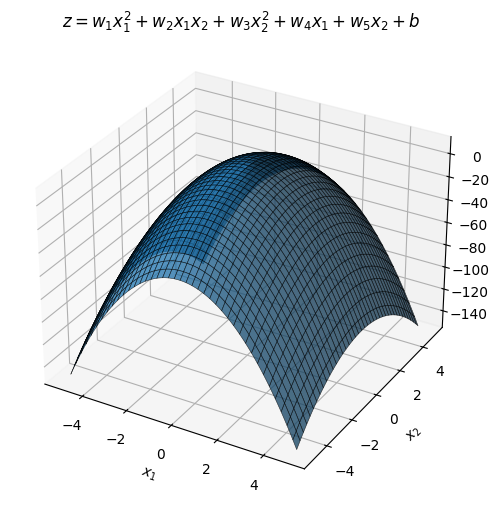

In [ ]:
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(U, V, Z, alpha=0.75, edgecolor='k', linewidth=0.4)

ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.set_zlabel(r'$z$')
ax.set_title(r'$z=w_1x_1^2+w_2x_1x_2+w_3x_2^2+w_4x_1+w_5x_2+b$')

plt.show()

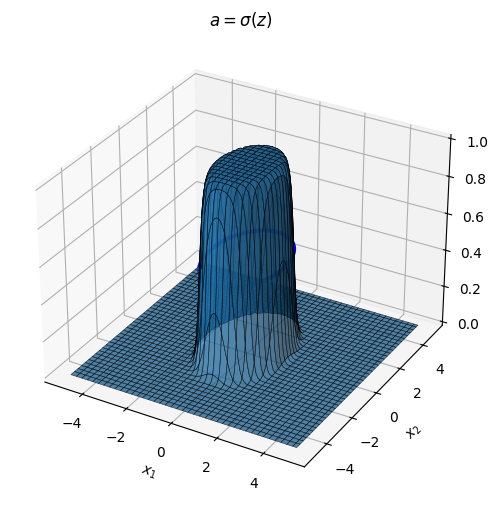

In [ ]:
A = 1 / (1 + np.exp(-Z))

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(U, V, A, alpha=0.75, edgecolor='k', linewidth=0.4)
ax.contour(U, V, A, levels=[0.5], colors='b', linewidths=3)

ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.set_zlabel(r'$a$')
ax.set_title(r'$a=\sigma(z)$')

plt.show()

![figure](images/02_ex3_1.png)